In [2]:
!nvidia-smi

Fri Oct 16 10:55:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
import numba, numpy as np
from numba import cuda

print("numba", numba.__version__)
print("cuda.is_available:", cuda.is_available())
dev = cuda.get_current_device()
print("карта:", dev.name.decode() if isinstance(dev.name, bytes) else dev.name)
print("мультипроцесорів (SM):", dev.MULTIPROCESSOR_COUNT, "| розмір варпу:", dev.WARP_SIZE)

numba 0.61.2
cuda.is_available: True
карта: Tesla T4
мультипроцесорів (SM): 40 | розмір варпу: 32


In [5]:
@cuda.jit
def mandelbrot_gpu(out, xmin, xmax, ymin, ymax, max_iter):
    x, y = cuda.grid(2)                              # хто я в сітці
    if x >= out.shape[1] or y >= out.shape[0]:       # ⚠️ перевірка меж — обов'язкова
        return
    cx = xmin + (xmax - xmin) * x / out.shape[1]
    cy = ymin + (ymax - ymin) * y / out.shape[0]
    zx = 0.0
    zy = 0.0
    n = 0
    while zx * zx + zy * zy <= 4.0 and n < max_iter:
        zx, zy = zx * zx - zy * zy + cx, 2.0 * zx * zy + cy
        n += 1
    out[y, x] = n

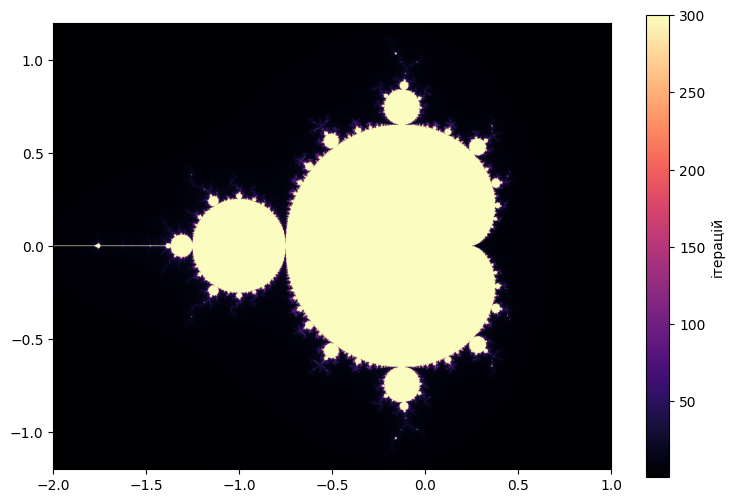

In [6]:
import numpy as np

XMIN, XMAX, YMIN, YMAX = -2.0, 1.0, -1.2, 1.2
MAX_ITER = 300
W, H = 1200, 800

potokiv = (16, 16)                                   # 256 потоків у блоці
blokiv = ((W + 15) // 16, (H + 15) // 16)

d_out = cuda.device_array((H, W), dtype=np.int32)
mandelbrot_gpu[blokiv, potokiv](d_out, XMIN, XMAX, YMIN, YMAX, MAX_ITER)
out = d_out.copy_to_host()

import matplotlib.pyplot as plt
plt.figure(figsize=(9, 6))
plt.imshow(out, cmap="magma", extent=(XMIN, XMAX, YMIN, YMAX))
plt.colorbar(label="ітерацій")
plt.show()

In [7]:
from numba import njit, prange

@njit(parallel=True, cache=True)
def mandelbrot_cpu(W, H, xmin, xmax, ymin, ymax, max_iter):
    out = np.empty((H, W), np.int32)
    for j in prange(H):
        for i in range(W):
            cx = xmin + (xmax - xmin) * i / W
            cy = ymin + (ymax - ymin) * j / H
            zx = 0.0
            zy = 0.0
            n = 0
            while zx * zx + zy * zy <= 4.0 and n < max_iter:
                zx, zy = zx * zx - zy * zy + cx, 2.0 * zx * zy + cy
                n += 1
            out[j, i] = n
    return out

mandelbrot_cpu(16, 16, XMIN, XMAX, YMIN, YMAX, MAX_ITER)          # компіляція
ref = mandelbrot_cpu(W, H, XMIN, XMAX, YMIN, YMAX, MAX_ITER)

rozbizhnyh = int((out != ref).sum())
print("розбіжних точок:", rozbizhnyh, "з", W * H)

розбіжних точок: 2 з 960000


In [8]:
import time

def zamir_gpu(W, H, blok=(16, 16), n=3):
    host = np.empty((H, W), np.int32)
    blokiv = ((W + blok[0] - 1) // blok[0], (H + blok[1] - 1) // blok[1])
    best = None
    for _ in range(n):
        t0 = time.perf_counter()
        d_out = cuda.to_device(host)
        cuda.synchronize()
        t_tudy = time.perf_counter() - t0

        t0 = time.perf_counter()
        mandelbrot_gpu[blokiv, blok](d_out, XMIN, XMAX, YMIN, YMAX, MAX_ITER)
        cuda.synchronize()
        t_yadro = time.perf_counter() - t0

        t0 = time.perf_counter()
        res = d_out.copy_to_host()
        t_nazad = time.perf_counter() - t0

        if best is None or sum(best[:3]) > t_tudy + t_yadro + t_nazad:
            best = (t_tudy, t_yadro, t_nazad, res)
    return best

t_tudy, t_yadro, t_nazad, out = zamir_gpu(W, H)
razom = t_tudy + t_yadro + t_nazad
print(f"копіювання туди   {t_tudy*1000:8.2f} мс")
print(f"обчислення        {t_yadro*1000:8.2f} мс")
print(f"копіювання назад  {t_nazad*1000:8.2f} мс")
print(f"разом             {razom*1000:8.2f} мс   копіювання = {100*(t_tudy+t_nazad)/razom:.0f} %")

копіювання туди       1.02 мс
обчислення           15.19 мс
копіювання назад      1.00 мс
разом                17.21 мс   копіювання = 12 %


In [13]:
d = cuda.to_device(np.empty((H, W), np.int32))
cuda.synchronize()
t0 = time.perf_counter()
mandelbrot_gpu[blokiv, potokiv](d, XMIN, XMAX, YMIN, YMAX, MAX_ITER)
bez = time.perf_counter() - t0        # ⚠️ виміряли лише запуск
cuda.synchronize()
z = time.perf_counter() - t0          # справжній час
print(f"без synchronize {bez*1000:.3f} мс · з synchronize {z*1000:.3f} мс")

без synchronize 0.734 мс · з synchronize 15.787 мс


In [10]:
print("| розмір | туди, мс | ядро, мс | назад, мс | частка копіювання |")
print("|---|---|---|---|---|")
for w, h in ((300, 200), (1200, 800), (3000, 2000)):
    tt, ty, tn, _ = zamir_gpu(w, h)
    s = tt + ty + tn
    print(f"| {w}x{h} | {tt*1000:.2f} | {ty*1000:.2f} | {tn*1000:.2f} | {100*(tt+tn)/s:.0f} % |")

| розмір | туди, мс | ядро, мс | назад, мс | частка копіювання |
|---|---|---|---|---|
| 300x200 | 0.36 | 2.13 | 0.13 | 19 % |
| 1200x800 | 1.14 | 15.08 | 1.15 | 13 % |
| 3000x2000 | 7.81 | 51.61 | 5.89 | 21 % |
